# Game CFO lab: growth, liquidity, and a $1MM cash target

This notebook treats user acquisition as a capital-allocation problem for a synthetic IAP and ad-supported game. The CFO starts with **$400k**, protects a **$300k minimum bank balance**, and makes weekly channel decisions over 26 weeks.

Two constrained plans are solved:

1. Maximize active-player growth at day 181 while the bank balance never breaches the floor and the company ends the 365-day horizon above its starting cash.
2. Find the minimum acquisition spend needed to reach **$1MM in the bank by day 365**.

Theseus supplies the cohort cash-flow response for every channel. SciPy's linear optimizer selects the spend schedule. All inputs are deterministic synthetic assumptions, not market benchmarks.

### Start here and related reading

- [Theseus API introduction and walkthrough](../../Theseus_Walkthrough.ipynb)
- [Building a marketing P&L using LTV and ROAS](https://mobiledevmemo.com/ltv-roas-marketing-p-and-l/)
- [Optimization models in digital advertising](https://mobiledevmemo.com/optimization-models-in-digital-advertising/)

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.figure import Figure
from scipy.optimize import linprog

import theseus_growth as tg

%matplotlib inline
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "pyproject.toml").exists())
DATA = ROOT / "examples" / "data" / "game"

channels = pd.read_csv(DATA / "channel_assumptions.csv").set_index("channel")
curves = pd.read_csv(DATA / "curves.csv")
baseline_cohorts = pd.read_csv(DATA / "cohorts.csv")
baseline_spend = pd.read_csv(DATA / "acquisition_spend.csv")
assumptions = pd.read_csv(DATA / "cash_assumptions.csv").set_index("assumption")["value"]

STARTING_CASH = float(assumptions["starting_cash"])
MINIMUM_CASH = float(assumptions["minimum_cash"])
TARGET_CASH = float(assumptions["target_cash"])
DAILY_OPERATING_CASH_FLOW = float(assumptions["daily_non_marketing_cash_flow"])
PLANNING_WEEKS = int(assumptions["planning_weeks"])
FORECAST_END = int(assumptions["forecast_days"] - 1)
GROWTH_DAY = 181

display(channels)
display(pd.DataFrame({
    "starting_cash": [STARTING_CASH],
    "cash_floor": [MINIMUM_CASH],
    "cash_target": [TARGET_CASH],
    "daily_non_marketing_cash_flow": [DAILY_OPERATING_CASH_FLOW],
}))

,curve_id,cpi,max_weekly_spend,retention_floor,retention_decay_days,iap_per_active_user_day,ads_per_active_user_day,variable_cost_per_active_user_day
channel,,,,,,,,
paid_social,game_paid_social,2.40,45000,0.01,11,0.20,0.06,0.01
ad_network,game_ad_network,1.45,30000,0.01,8,0.12,0.09,0.01
search,game_search,2.85,25000,0.01,17,0.26,0.04,0.01


,starting_cash,cash_floor,cash_target,daily_non_marketing_cash_flow
0,"400,000.00","300,000.00","1,000,000.00",-350.00


## Turn Theseus curves into optimizer coefficients

The model is linear at a fixed CPI and curve: a $10,000 cohort has exactly 10,000 times the cash-flow response of a $1 cohort. We therefore ask Theseus to forecast one **$1 acquisition unit** per channel, then shift those daily responses to each possible acquisition week.

This retains the full cohort timing. The optimizer sees the upfront spend, delayed IAP and ad receipts, live-ops costs, retention, and channel capacity—not just a single LTV/CAC ratio.

In [2]:
unit_cohorts, unit_spend = [], []
for channel, spec in channels.iterrows():
    unit_cohorts.append({
        "cohort_id": channel,
        "acquisition_period": 0,
        "population": 1 / spec["cpi"],
        "curve_id": spec["curve_id"],
        "channel": channel,
    })
    unit_spend.append({"period": 0, "cohort_id": channel, "amount": 1.0})

unit_result = tg.forecast(
    pd.DataFrame(unit_cohorts), curves,
    acquisition_spend=pd.DataFrame(unit_spend),
    as_of=0, forecast_end=FORECAST_END, start=0,
)

decision_rows, cumulative_columns, active_coefficients = [], [], []
for week, acquisition_day in enumerate(range(0, PLANNING_WEEKS * 7, 7)):
    for channel, spec in channels.iterrows():
        unit_rows = unit_result.contributions.query(
            "cohort_id == @channel and category != 'activity'"
        )
        daily_response = (
            unit_rows.groupby("age")["pnl_amount"].sum()
            .reindex(range(FORECAST_END + 1), fill_value=0).to_numpy(copy=True)
        )
        daily_response[0] -= 1.0  # acquisition spend at age zero
        shifted = np.zeros(FORECAST_END + 1)
        shifted[acquisition_day:] = daily_response[: FORECAST_END + 1 - acquisition_day]
        cumulative_columns.append(np.cumsum(shifted))

        active = unit_result.contributions.query(
            "cohort_id == @channel and component == 'retention'"
        ).set_index("age")["amount"]
        active_coefficients.append(float(active.get(GROWTH_DAY - acquisition_day, 0)))
        decision_rows.append({
            "channel": channel,
            "week": week,
            "period": acquisition_day,
            "max_spend": float(spec["max_weekly_spend"]),
        })

decisions = pd.DataFrame(decision_rows)
cumulative_response = np.column_stack(cumulative_columns)
active_coefficients = np.asarray(active_coefficients)
base_cash = STARTING_CASH + np.cumsum(
    np.repeat(DAILY_OPERATING_CASH_FLOW, FORECAST_END + 1)
)
bounds = list(zip(np.zeros(len(decisions)), decisions["max_spend"]))

unit_economics = []
for channel, spec in channels.iterrows():
    rows = unit_result.contributions.query("cohort_id == @channel")
    revenue = rows.loc[rows["category"].eq("revenue"), "amount"].sum()
    contribution = rows.loc[rows["category"].ne("activity"), "pnl_amount"].sum()
    unit_economics.append({
        "channel": channel,
        "CPI": spec["cpi"],
        "365d revenue / spend": revenue,
        "365d contribution / spend": contribution,
        "365d marketing profit / spend": contribution - 1,
    })
display(pd.DataFrame(unit_economics).set_index("channel"))

,CPI,365d revenue / spend,365d contribution / spend,365d marketing profit / spend
channel,,,,
paid_social,2.40,1.59,1.52,0.52
ad_network,1.45,1.58,1.50,0.50
search,2.85,2.35,2.25,1.25


## Decision 1: maximize growth without risking the company

The objective is active players on day 181. There are two sets of constraints:

- Bank cash must stay at or above the floor on **every day**, not merely at quarter-end.
- Ending cash after fixed operating outflows must be at least the initial $400k, so growth is profitable within the modeled horizon.

Weekly channel limits stand in for inventory, audience size, and operational pacing.

In [3]:
growth_A = np.vstack([-cumulative_response, -cumulative_response[-1]])
growth_b = np.r_[
    base_cash - MINIMUM_CASH,
    base_cash[-1] - STARTING_CASH,
]
growth_solution = linprog(
    c=-active_coefficients,
    A_ub=growth_A,
    b_ub=growth_b,
    bounds=bounds,
    method="highs",
)
assert growth_solution.success, growth_solution.message

growth_plan = decisions.copy()
growth_plan["spend"] = growth_solution.x
growth_cash_lp = base_cash + cumulative_response @ growth_solution.x

assert growth_cash_lp.min() >= MINIMUM_CASH - 0.01
assert growth_cash_lp[-1] >= STARTING_CASH - 0.01
display(growth_plan.pivot(index="week", columns="channel", values="spend").head(10))
print(f"Total acquisition spend: ${growth_plan['spend'].sum():,.0f}")
print(f"Active players on day {GROWTH_DAY}: {active_coefficients @ growth_solution.x:,.0f}")
print(f"Minimum bank balance: ${growth_cash_lp.min():,.0f}")
print(f"Ending bank balance: ${growth_cash_lp[-1]:,.0f}")

channel,ad_network,paid_social,search
week,,,
0,"30,000.00","45,000.00","25,000.00"
1,"30,000.00","17,522.68","25,000.00"
2,"30,000.00","22,377.23","25,000.00"
3,"30,000.00","34,879.11","25,000.00"
4,"30,000.00","45,000.00","25,000.00"
5,"30,000.00","45,000.00","25,000.00"
6,"30,000.00","45,000.00","25,000.00"
7,"30,000.00","45,000.00","25,000.00"
8,"30,000.00","45,000.00","25,000.00"


Total acquisition spend: $2,539,779
Active players on day 181: 68,331
Minimum bank balance: $300,000
Ending bank balance: $1,812,424


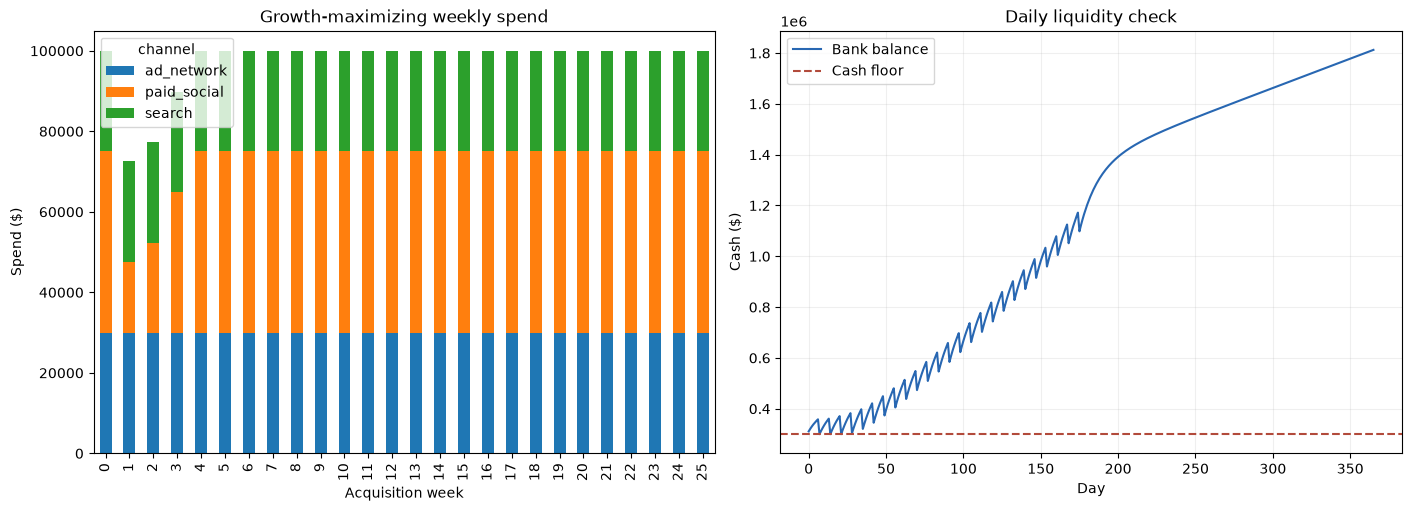

In [4]:
def forecast_plan(plan):
    cohort_rows, spend_rows = [], []
    for row in plan.loc[plan["spend"].gt(0.01)].itertuples(index=False):
        spec = channels.loc[row.channel]
        cohort_id = f"{row.channel}-w{int(row.week):02d}"
        cohort_rows.append({
            "cohort_id": cohort_id,
            "acquisition_period": int(row.period),
            "population": row.spend / spec["cpi"],
            "curve_id": spec["curve_id"],
            "channel": row.channel,
            "week": int(row.week),
        })
        spend_rows.append({
            "period": int(row.period), "cohort_id": cohort_id,
            "amount": row.spend, "channel": row.channel,
        })
    return tg.forecast(
        pd.DataFrame(cohort_rows), curves,
        acquisition_spend=pd.DataFrame(spend_rows),
        as_of=0, forecast_end=FORECAST_END, start=0,
    )


def bank_cash(result):
    timeline = result.timeline()
    operating = np.cumsum(np.repeat(DAILY_OPERATING_CASH_FLOW, len(timeline)))
    return STARTING_CASH + operating + timeline["cumulative_marketing_pnl"].to_numpy()


growth_result = forecast_plan(growth_plan)
growth_cash = bank_cash(growth_result)
np.testing.assert_allclose(growth_cash, growth_cash_lp, atol=0.01)

growth_figure = Figure(figsize=(14, 5), layout="constrained")
spend_ax, cash_ax = growth_figure.subplots(1, 2)
growth_plan.pivot(index="week", columns="channel", values="spend").plot(
    kind="bar", stacked=True, ax=spend_ax, title="Growth-maximizing weekly spend"
)
spend_ax.set(xlabel="Acquisition week", ylabel="Spend ($)")
cash_ax.plot(growth_cash, color="#2867B2", label="Bank balance")
cash_ax.axhline(MINIMUM_CASH, color="#B24A3B", linestyle="--", label="Cash floor")
cash_ax.set(title="Daily liquidity check", xlabel="Day", ylabel="Cash ($)")
cash_ax.legend()
cash_ax.grid(alpha=0.2)
display(growth_figure)

## Decision 2: reach $1MM with the least acquisition capital

Now the terminal cash target becomes a constraint and total acquisition spend becomes the objective to minimize. This is a useful goal-seek formulation: it answers how much capital—and which cohorts—are required to get from $400k to $1MM by day 365 without violating the same liquidity floor.

In [5]:
target_A = np.vstack([-cumulative_response, -cumulative_response[-1]])
target_b = np.r_[
    base_cash - MINIMUM_CASH,
    base_cash[-1] - TARGET_CASH,
]
target_solution = linprog(
    c=np.ones(len(decisions)),
    A_ub=target_A,
    b_ub=target_b,
    bounds=bounds,
    method="highs",
)
assert target_solution.success, target_solution.message

target_plan = decisions.copy()
target_plan["spend"] = target_solution.x
target_result = forecast_plan(target_plan)
target_cash = bank_cash(target_result)

assert target_cash.min() >= MINIMUM_CASH - 0.01
assert target_cash[-1] >= TARGET_CASH - 0.01
print(f"Minimum acquisition spend required: ${target_plan['spend'].sum():,.0f}")
print(f"Minimum bank balance: ${target_cash.min():,.0f}")
print(f"Ending bank balance: ${target_cash[-1]:,.0f}")
display(
    target_plan.groupby("channel")["spend"].sum()
    .sort_values(ascending=False).rename("total_spend").to_frame()
)

Minimum acquisition spend required: $650,903
Minimum bank balance: $363,991
Ending bank balance: $1,000,000


,total_spend
channel,
search,"650,000.00"
paid_social,903.08
ad_network,0.00


,acquisition_spend,players_acquired,active_players_day_181,minimum_cash,ending_cash,marketing_pnl
scenario,,,,,,
Current synthetic plan,"1,157,500.00","547,276.92","31,642.67","346,909.46","953,911.77","682,011.77"
Maximum growth,"2,539,779.03","1,228,409.14","68,330.64","300,000.00","1,812,424.35","1,540,524.35"
$1MM target / minimum spend,"650,903.08","228,446.46","21,410.74","363,991.09","1,000,000.00","728,100.00"


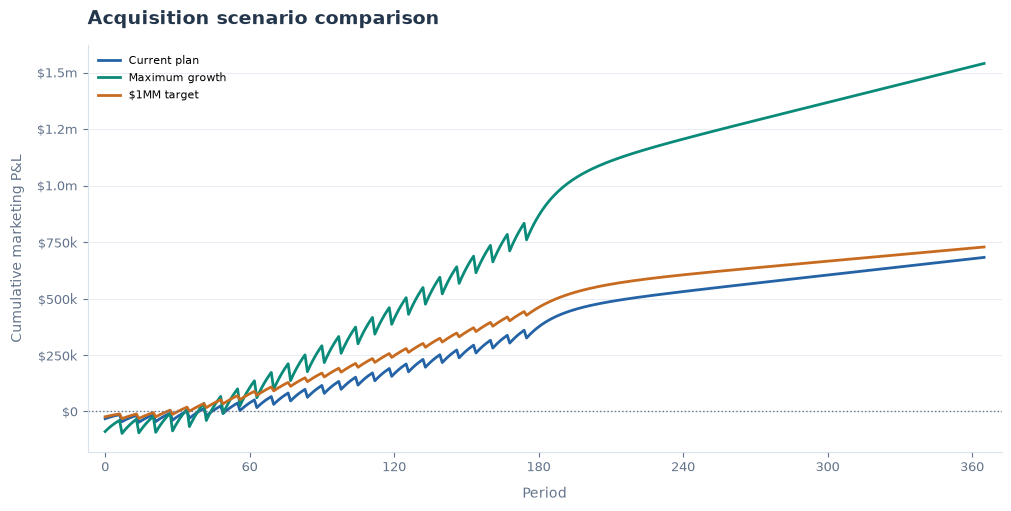

In [6]:
baseline_result = tg.forecast(
    baseline_cohorts, curves, acquisition_spend=baseline_spend,
    as_of=0, forecast_end=FORECAST_END, start=0,
)


def scenario_row(name, result):
    cash = bank_cash(result)
    active = result.contributions.query(
        "component == 'retention' and period == @GROWTH_DAY"
    )["amount"].sum()
    return {
        "scenario": name,
        "acquisition_spend": result.acquisition_spend["amount"].sum(),
        "players_acquired": result.cohorts["population"].sum(),
        f"active_players_day_{GROWTH_DAY}": active,
        "minimum_cash": cash.min(),
        "ending_cash": cash[-1],
        "marketing_pnl": result.timeline()["marketing_pnl"].sum(),
    }


summary = pd.DataFrame([
    scenario_row("Current synthetic plan", baseline_result),
    scenario_row("Maximum growth", growth_result),
    scenario_row("$1MM target / minimum spend", target_result),
]).set_index("scenario")
display(summary)

comparison = tg.viz.scenario_comparison({
    "Current plan": baseline_result,
    "Maximum growth": growth_result,
    "$1MM target": target_result,
})
display(comparison.figure)

## CFO interpretation

- The growth solution spends up to channel capacity where the delayed cohort cash flows still preserve the daily liquidity covenant.
- The $1MM goal-seek favors the highest incremental cash return available within the deadline; a high LTV channel can dominate even when its CPI is higher.
- These are underwriting outputs, not causal estimates. Real use should refresh curves from observed cohorts and add diminishing returns, payment timing, taxes, payroll, platform settlement delays, and uncertainty bands.
- The constraints are explicit and inspectable. Change the floor, deadline, channel caps, or target and rerun the optimizer—no chart-specific logic needs to change.